# How Gradient Variance Shapes Policy Optimization

In this blogpost, we investigate how reward baselines affect the learning dynamics of policy-gradient algorithms applied to multi-armed bandit problems. Multi-armed bandits are a class of reinforcement learning problems in which an agent selects one of a fixed set of actions, each producing a stochastic reward. Policy-gradient algorithms directly optimize a parameterized policy to maximize expected reward, unlike value-based methods, which estimate the expected reward associated with each action. 

The optimization objective is:

$$
J(\theta) = \mathbb{E}_{\pi_\theta}[R]
$$

where $\theta$ represents the policy parameters.  We can optimize this objective using gradient ascent:

$$
\theta_{t+1} = \theta_t + \alpha \nabla_\theta J(\theta_t)
$$

where $\alpha$ is the learning rate.

However, the reward distributions are unknown, so we cannot directly evaluate the gradient of the expected reward. Fortunately, the log-derivative trick allows us to express the gradient in a form that can be estimated from sampled actions and rewards.

For a multi-armed bandit:

$$
J(\theta) = \sum_a \pi_\theta(a)q_*(a)
$$

where $q_*(a)$ is the true expected reward associated with action $a$. Differentiating with respect to $\theta$:

$$
\begin{aligned}
\nabla_\theta J(\theta)
&= \sum_a q_*(a)\nabla_\theta \pi_\theta(a) \\
&= \sum_a \pi_\theta(a)q_*(a)\nabla_\theta \log \pi_\theta(a) \\
&= \mathbb{E}_{\pi_\theta}\left[R\nabla_\theta\log\pi_\theta(A)\right]
\end{aligned}
$$

This gives us an unbiased Monte Carlo estimator and the corresponding update rule:

$$
\theta_{t+1} =
\theta_t + \alpha R_t \nabla_\theta \log \pi_{\theta_t}(A_t)
$$

## Gradient Bandits

A simple policy parameterization assigns a scalar preference $H_t(a)$ to each action. Unlike action-value estimates, these preferences do not directly represent expected rewards. Instead, they determine the probability of selecting each action through the softmax function:

$$
\pi_t(a) = \frac{\exp(H_t(a))}{\sum_b \exp(H_t(b))}
$$

For this parameterization, the gradient of the log-probability of the selected action is:

$$
\frac{\partial \log \pi_t(A_t)}{\partial H_t(a)}
=
\mathbb{1}[a=A_t] - \pi_t(a)
$$

where $\mathbb{1}[a=A_t]$ equals 1 when $a$ is the selected action and 0 otherwise.

Substituting this into the stochastic gradient update gives:

$$
H_{t+1}(a)
=
H_t(a)
+
\alpha R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

When the observed reward is positive, the selected action's preference increases while the preferences of the other actions decrease. Negative rewards reverse the direction of these updates.

Let's implement a $k$-armed bandit environment to investigate how this algorithm behaves. Each arm produces stochastic rewards with a fixed expected value $q_*(a)$ and unit variance. The expected rewards are sampled independently from a normal distribution:

$$
q_*(a)\sim\mathcal N(\mu,1)
$$

The environment's mean parameter $\mu$ defaults to zero, but we can vary it to shift the expected rewards of all actions by the same amount. Since adding a constant to every action's expected reward does not change which action is optimal, we might expect the learning algorithm to behave similarly across different reward offsets.

In [1]:
from typing import NamedTuple
import jax
import jax.numpy as jnp


class KArmedBandit:
    def __init__(self, k=10, mean=0.0):
        self.k = k
        self.mean = mean

    def reset(self, key):
        q_star = self.mean + jax.random.normal(key, shape=(self.k,))
        observation = 0
        env_state = q_star
        return env_state, observation

    def step(self, key, env_state, action):
        reward = env_state[action] + jax.random.normal(key) 
        observation = 0
        terminated = False

        info = {}

        return env_state, observation, reward, terminated, info


Next, let's code up the policy gradient agent.

In [2]:


class GradientBanditState(NamedTuple):
    H: jax.Array
    N: jax.Array


class GradientBanditAgent:
    def __init__(self, k=10, alpha=0.1):
        self.k = k
        self.alpha = alpha
        

    def init(self):
        # Initialize action preferences H to zeros
        return GradientBanditState(
                H=jnp.zeros(self.k),
                N=jnp.array(0, dtype=jnp.int32)
        )

    def select_action(self, key, agent_state: GradientBanditState):
        # Sample an action from softmax(H)
        H,  _ = agent_state
        probs = jax.nn.softmax(H)
        action = jax.random.choice(key, a=self.k, p=probs)
        return action

    def update(self, agent_state, action, reward):
        H, N = agent_state
        probs = jax.nn.softmax(H)
        mask = jnp.zeros(self.k).at[action].set(1)
        H = H + self.alpha * (reward) * (mask - probs)
        return GradientBanditState(
            H=H,
            N=N+1
        )

Let's train the gradient-bandit agent under four different reward offsets. For each offset, we'll conduct 2,000 independent runs, each consisting of 1,000 training steps.

In [3]:
k = 10
num_runs = 2000
num_steps = 1000

means = [0.0, 2.0, 4.0, 8.0]

agent = GradientBanditAgent(
    k=k,
    alpha=0.1,
)

env = KArmedBandit(k=k, mean=0.0)

def run_experiment(key, reward_offset):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    optimal_action = jnp.argmax(env_state)

    def training_step(carry, _):
        key, agent_state, env_state = carry

        log_probs = jax.nn.log_softmax(agent_state.H)
        probs = jnp.exp(log_probs)
        entropy = -jnp.sum(probs * log_probs)

        key, action_key, reward_key = jax.random.split(key, 3)

        action = agent.select_action(action_key, agent_state)

        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        reward = reward + reward_offset

        agent_state = agent.update(
            agent_state, action, reward
        )

        is_optimal = action == optimal_action

        return (
            key, agent_state, env_state
        ), (is_optimal, entropy)

    initial_carry = (key, agent_state, env_state)

    _, (optimal_actions, entropies) = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    return optimal_actions, entropies


key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

means = jnp.array([0.0, 2.0, 4.0, 8.0])

batched_experiment = jax.jit(
    jax.vmap(
        jax.vmap(run_experiment, in_axes=(0, None)),
        in_axes=(None, 0),
    )
)

optimal_actions, entropies = batched_experiment(keys, means)

mean_optimal = 100 * jnp.mean(optimal_actions, axis=1)
mean_entropy = jnp.mean(entropies, axis=1)


Let's plot the percentage of times the agent selects the optimal action over the course of training, for each reward offset.

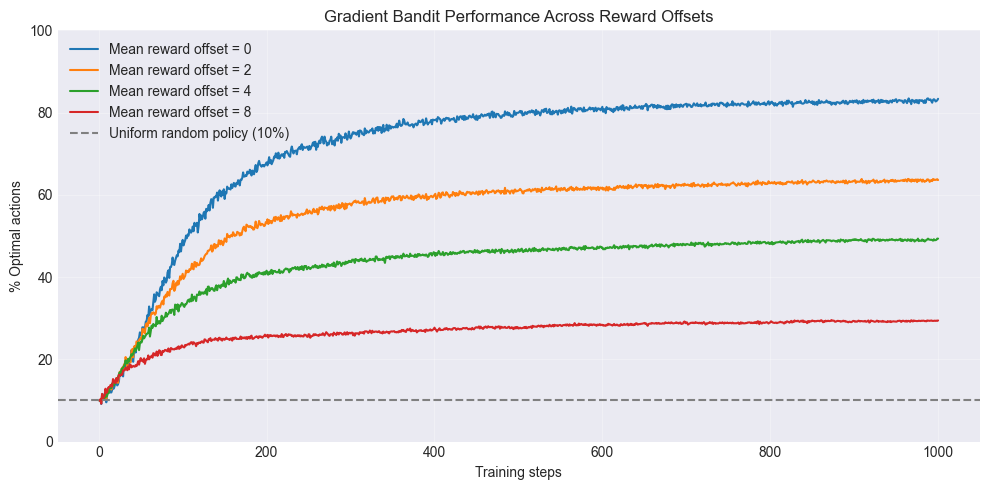

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display, HTML
plt.style.use('seaborn-v0_8-darkgrid')

plt.figure(figsize=(10, 5))

results = {
    float(mean): mean_optimal[i]
    for i, mean in enumerate(means)
}

steps = jnp.arange(1, num_steps + 1)

for mean, percentages in results.items():
    plt.plot(
        steps,
        percentages,
        label=f"Mean reward offset = {mean:.0f}",
    )

plt.axhline(
    y=100 / k,
    color="gray",
    linestyle="--",
    label="Uniform random policy (10%)",
)

plt.xlabel("Training steps")
plt.ylabel("% Optimal actions")
plt.title("Gradient Bandit Performance Across Reward Offsets")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Interestingly, the performance of the gradient-bandit algorithm deteriorates as we increase the mean reward, even though the differences between the expected rewards of the actions remain unchanged. Adding a constant to every action's reward distribution does not change which action is optimal. Nor does it change the expected policy gradient. So why should an algorithm that performs reasonably well when rewards are centered around zero perform so poorly when those same rewards are shifted upward? Let's look at a distribution of optimal-action selection frequencies for each experiment. 

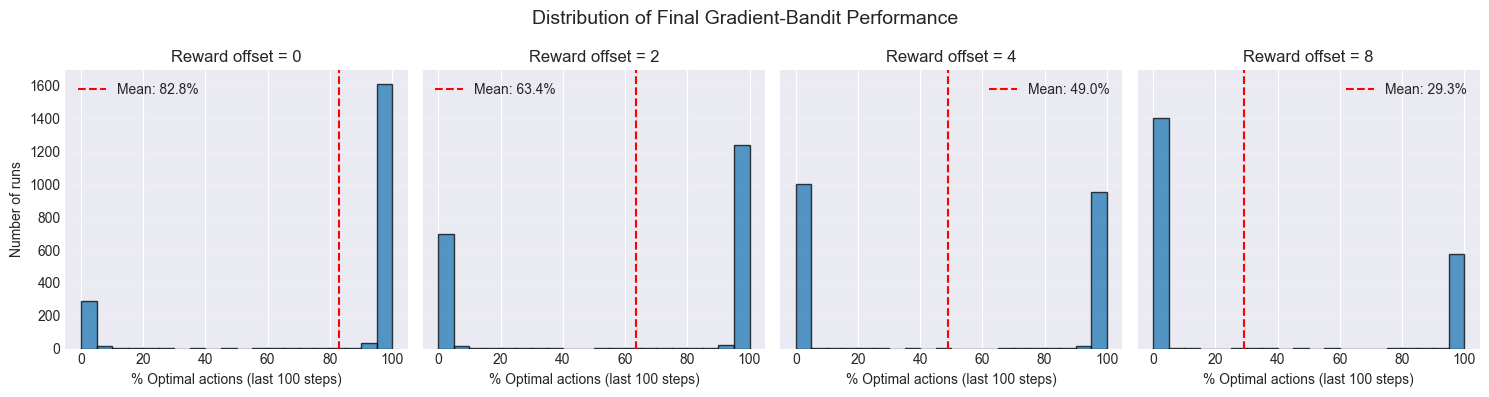

In [5]:
import numpy as np

final_optimal_pct = (
    100 * jnp.mean(optimal_actions[:, :, -100:], axis=2)
)

fig, axes = plt.subplots(
    1, 4, figsize=(15, 4), sharex=True, sharey=True
)

bins = np.arange(0, 105, 5)

for i, (ax, mean) in enumerate(zip(axes, means)):
    final_performance = np.asarray(final_optimal_pct[i])

    ax.hist(
        final_performance,
        bins=bins,
        edgecolor="black",
        alpha=0.75,
    )

    ax.axvline(
        final_performance.mean(),
        color="red",
        linestyle="--",
        label=f"Mean: {final_performance.mean():.1f}%",
    )

    ax.set_title(f"Reward offset = {float(mean):.0f}")
    ax.set_xlabel("% Optimal actions (last 100 steps)")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Number of runs")

fig.suptitle(
    "Distribution of Final Gradient-Bandit Performance",
    fontsize=14,
)

plt.tight_layout()
plt.show()


The distributions are strongly bimodal, with most runs either selecting the optimal action almost exclusively or rarely selecting it at all. As the mean reward increases, the distribution shifts increasingly toward zero optimal-action selection, suggesting that more runs fail to learn the optimal policy.

One possible explanation is that larger stochastic preference updates cause the policy to become prematurely concentrated on a suboptimal action.  A good way to test this hypothesis is to plot the average policy entropy for each experiment.


### Measuring Policy Entropy

We can measure the entropy of the policy, which quantifies how evenly the action-selection probabilities are distributed.

For a policy $\pi_t$, entropy is defined as:

$$
\mathcal H(\pi_t)=-\sum_a\pi_t(a)\log\pi_t(a)
$$

A policy that assigns equal probability to every action has maximum entropy. For our 10-armed bandit, this is:

$$
\mathcal H_{\max}=\log(10)\approx2.303
$$

Conversely, entropy approaches zero as the policy becomes concentrated on a single action.  Note that the entropy does not tell us whether the preferred action is optimal. It only measures how concentrated the policy is. We can calculate the policy entropy at each training step using the action probabilities obtained from the softmax function, then average these values across our 2,000 independent runs.

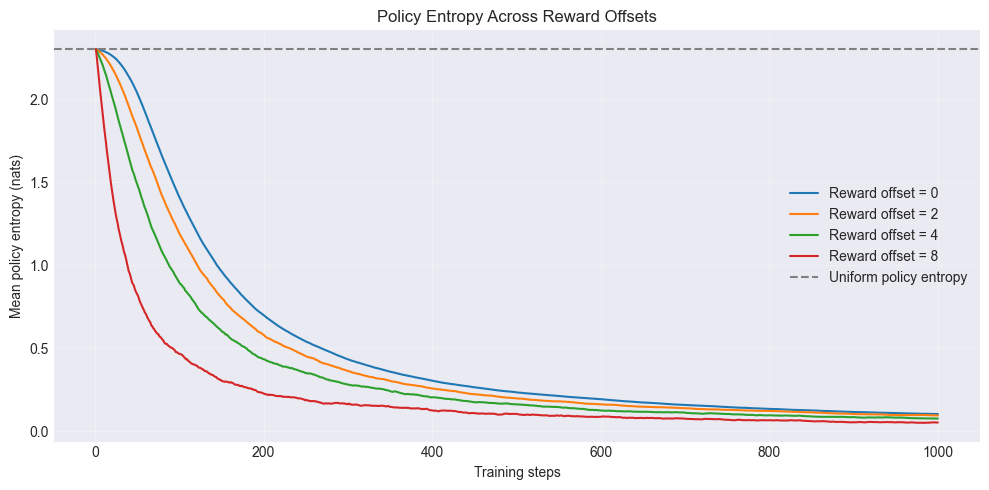

In [6]:
plt.figure(figsize=(10, 5))

steps = jnp.arange(1, num_steps + 1)

for i, mean in enumerate(means):
    plt.plot(
        steps,
        mean_entropy[i],
        label=f"Reward offset = {float(mean):.0f}",
    )

plt.axhline(
    y=float(jnp.log(k)),
    color="gray",
    linestyle="--",
    label="Uniform policy entropy",
)

plt.xlabel("Training steps")
plt.ylabel("Mean policy entropy (nats)")
plt.title("Policy Entropy Across Reward Offsets")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



Policy entropy decreases much more rapidly as the reward offset increases, indicating that the policy quickly concentrates its probability mass on a small number of actions. One possible explanation is that larger rewards produce more variable stochastic preference updates. To test this, we can measure the variance of the gradient updates.

### Measuring Gradient Variance

Recall the gradient-bandit update:

$$
H_{t+1}(a)
=
H_t(a)
+
\alpha R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

The stochastic gradient estimate for each action preference is therefore:

$$
\hat{g}_t(a)
=
R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

Since the gradient consists of one component for each action, we can measure its total variance as the sum of the variances of its individual components:

$$
V
=
\sum_a
\mathbb{E}\left[
\left(
\hat{g}_t(a)-\mathbb{E}[\hat{g}_t(a)]
\right)^2
\right]
$$

This measures how much the stochastic gradient estimates fluctuate around their expected values. To isolate the effect of reward offsets, we'll hold the policy fixed at the uniform distribution and estimate gradient variance from independently sampled actions and rewards. Unlike our previous experiments, we will not update the policy during this experiment. This allows us to measure how reward offsets affect gradient variance without the additional influence of changing action probabilities.

In [7]:

k = 10
num_samples = 100_000
reward_offsets = jnp.array([0.0, 2.0, 4.0, 8.0])

key = jax.random.key(123)
key, values_key, actions_key, noise_key = jax.random.split(key, 4)

# Fix one bandit problem, with q*(a) ~ N(0, 1)
q_star = jax.random.normal(values_key, (k,))

# Fix a uniform policy throughout the experiment
probs = jnp.ones(k) / k

# Same actions and reward noise for all offsets
actions = jax.random.choice(
    actions_key, k, shape=(num_samples,), p=probs
)
noise = jax.random.normal(noise_key, (num_samples,))

# Score function: grad_H log pi(A)
scores = jax.nn.one_hot(actions, k) - probs

def gradient_variance(gradients):
    mean_gradient = jnp.mean(gradients, axis=0)
    centered = gradients - mean_gradient
    return jnp.mean(jnp.sum(centered ** 2, axis=1))

variances = []

for offset in reward_offsets:
    rewards = q_star[actions] + noise + offset
    gradients = rewards[:, None] * scores
    variances.append(gradient_variance(gradients))

variances = jnp.stack(variances)

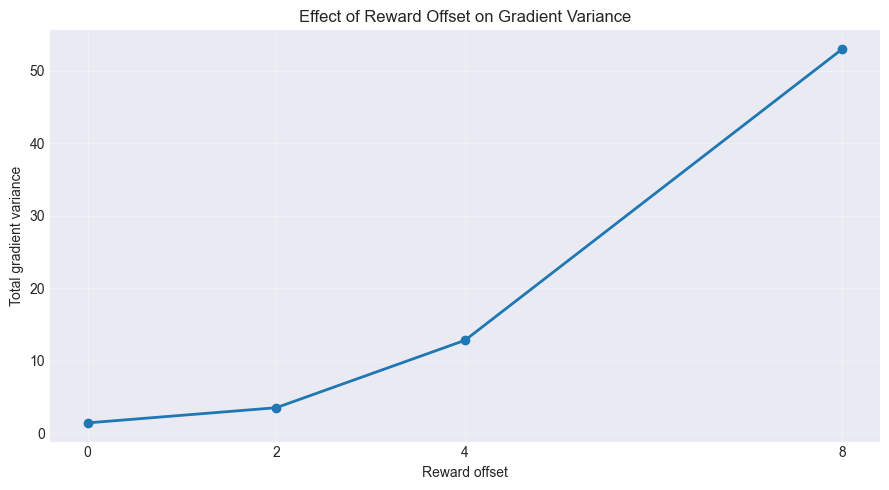

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.asarray(reward_offsets),
    np.asarray(variances),
    "o-",
    linewidth=2,
)

plt.xlabel("Reward offset")
plt.ylabel("Total gradient variance")
plt.title("Effect of Reward Offset on Gradient Variance")
plt.xticks(np.asarray(reward_offsets))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The results show that gradient variance increases rapidly with the reward offset, even though the differences between action values remain unchanged. In fact, the relationship is approximately quadratic. Larger reward offsets produce stochastic gradients with increasingly large magnitudes, despite leaving the expected policy gradient unchanged. Combining this result with our previous experiments suggests a possible explanation for the poor learning performance: increased gradient variance produces larger stochastic preference updates, which can cause the policy to become concentrated on an action before it has adequately explored the alternatives. This raises an important question: Can we reduce the variance of the stochastic gradient estimator without changing its expected value?

As we'll see, subtracting a reward baseline provides exactly such a mechanism.

## Introducing a Reward Baseline

Recall the stochastic gradient update:

$$
H_{t+1}(a) = H_t(a) + \alpha R_t \left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

Even when a suboptimal action is selected, a large positive reward can substantially increase its preference. This may cause the policy to become concentrated on that action before it has gathered enough evidence to identify the optimal one. One way to address this is to introduce a reward baseline. Instead of using the observed reward directly, we subtract a reference value $b_t$:

$$
H_{t+1}(a) = H_t(a) + \alpha (R_t-b_t)\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

A natural choice for the baseline is the average reward observed so far:

$$
b_t = \bar R_t = \frac{1}{t-1}\sum_{i=1}^{t-1}R_i
$$

For the first step, we initialize the baseline to zero. The running average can be updated incrementally, without storing previous rewards:

$$
\bar R_{t+1} = \bar R_t + \frac{1}{t}(R_t-\bar R_t)
$$

Importantly, the preference update uses the baseline before incorporating the current reward. With this modification, preference updates depend on whether the observed reward is better or worse than the agent's historical average, rather than on its absolute magnitude. 

### Why Doesn't a Baseline Change the Expected Policy Gradient?

To see why, recall that our optimization objective is the expected reward:

$$
J(\theta) = \mathbb{E}_{\pi_\theta}[R]
$$

Using the log-derivative identity, we previously derived:

$$
\nabla_\theta J(\theta)
=
\mathbb{E}_{\pi_\theta}
\left[R\nabla_\theta\log\pi_\theta(A)\right]
$$

Now suppose we subtract a baseline $b$ that does not depend on the sampled action:

$$
\mathbb{E}_{\pi_\theta}
\left[(R-b)\nabla_\theta\log\pi_\theta(A)\right]
$$

Expanding the expectation:

$$
=
\mathbb{E}_{\pi_\theta}
\left[R\nabla_\theta\log\pi_\theta(A)\right]
-
b\mathbb{E}_{\pi_\theta}
\left[\nabla_\theta\log\pi_\theta(A)\right]
$$

The crucial observation is that the second term is zero. To demonstrate this, recall that:

$$
\nabla_\theta\log\pi_\theta(a)
=
\frac{\nabla_\theta\pi_\theta(a)}{\pi_\theta(a)}
$$

Therefore:

$$
\begin{aligned}
\mathbb{E}_{\pi_\theta}
\left[\nabla_\theta\log\pi_\theta(A)\right]
&=
\sum_a\pi_\theta(a)\nabla_\theta\log\pi_\theta(a)\\
&=
\sum_a\nabla_\theta\pi_\theta(a)\\
&=
\nabla_\theta\sum_a\pi_\theta(a)\\
&=
\nabla_\theta 1\\
&=0
\end{aligned}
$$

Thus, both gradient estimators have exactly the same expectation at any fixed policy, provided the baseline is independent of the currently sampled action. This also applies to our running average reward baseline, since it is calculated from observations preceding the current action selection.

## So Does the Baseline Help? 
Let's modify our gradient-bandit agent to incorporate the reward baseline into its preference updates.

In [ ]:
class GradientBanditState(NamedTuple):
    H: jax.Array
    avg_reward: jax.Array
    N: jax.Array


class GradientBanditAgent:
    def __init__(self, k=10, alpha=0.1, use_baseline=True):
        self.k = k
        self.alpha = alpha
        self.use_baseline = use_baseline
        

    def init(self):
        # Initialize action preferences H to zeros
        return GradientBanditState(
                H=jnp.zeros(self.k),
                avg_reward=jnp.array(0.0),
                N=jnp.array(0, dtype=jnp.int32)
        )

    def select_action(self, key, agent_state: GradientBanditState):
        # Sample an action from softmax(H)
        H, _, _ = agent_state
        probs = jax.nn.softmax(H)
        action = jax.random.choice(key, a=self.k, p=probs)
        return action

    def update(self, agent_state, action, reward):
        H, avg_reward, N = agent_state
        probs = jax.nn.softmax(H)
        mask = jnp.zeros(self.k).at[action].set(1)
        baseline = avg_reward if self.use_baseline else 0.0
        H = H + self.alpha * (reward - avg_reward) * (mask - probs)
        avg_reward = avg_reward + (reward - baseline) / (N + 1)
        return GradientBanditState(
            H=H,
            avg_reward=avg_reward,
            N=N+1
        )

Let's compare how frequently the agents select the optimal action during training, with and without a reward baseline. We will use a fixed gradient offset of 4.0.

In [25]:

# Same environment and experimental configuration
env = KArmedBandit(k=10, mean=4.0)

configurations = {
    "Without baseline": GradientBanditAgent(
        k=10, alpha=0.1, use_baseline=False
    ),
    "With baseline": GradientBanditAgent(
        k=10, alpha=0.1, use_baseline=True
    ),
}


def run_experiment(key, agent):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    optimal_action = jnp.argmax(env_state)

    def training_step(carry, _):
        key, agent_state, env_state = carry

        key, action_key, reward_key = jax.random.split(key, 3)

        action = agent.select_action(action_key, agent_state)

        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        agent_state = agent.update(
            agent_state, action, reward
        )

        is_optimal = action == optimal_action

        return (key, agent_state, env_state), is_optimal

    initial_carry = (key, agent_state, env_state)

    _, optimal_actions = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    return optimal_actions


key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

results = {}

for name, agent in configurations.items():
    batched_experiment = jax.jit(
        jax.vmap(lambda run_key: run_experiment(run_key, agent))
    )

    optimal_actions = batched_experiment(keys)
    results[name] = 100 * jnp.mean(optimal_actions, axis=0)


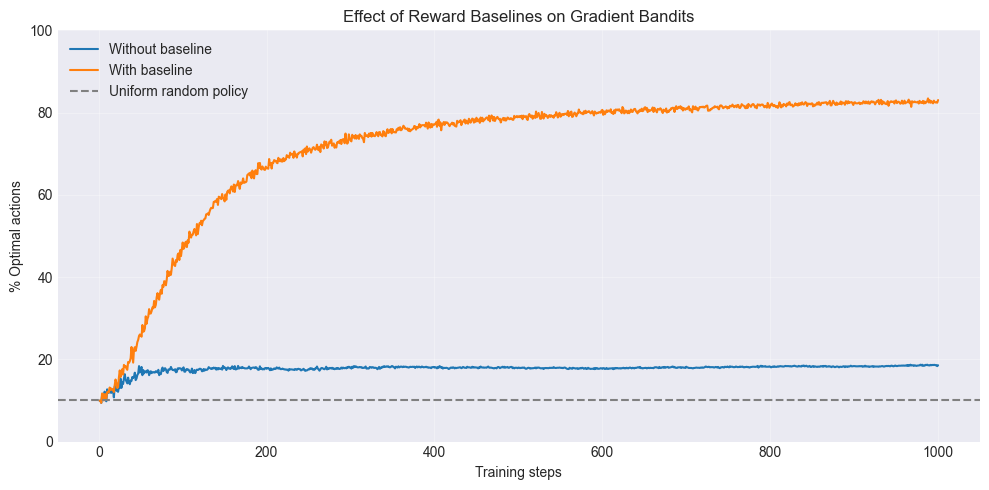

In [26]:
plt.figure(figsize=(10, 5))

steps = jnp.arange(1, num_steps + 1)

for name, percentages in results.items():
    plt.plot(steps, percentages, label=name)

plt.axhline(
    100 / k,
    color="gray",
    linestyle="--",
    label="Uniform random policy",
)

plt.xlabel("Training steps")
plt.ylabel("% Optimal actions")
plt.title("Effect of Reward Baselines on Gradient Bandits")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The plot shows that introducing a reward baseline substantially increases the frequency with which the agent selects the optimal action.

## Looking Across Reward Offsets
Let's compare the percentage of optimal actions selected across different reward offsets.

In [12]:
k = 10
num_runs = 2000
num_steps = 1000
alpha = 0.1

reward_means = [0.0, 2.0, 4.0, 8.0]


def run_experiment(key, env, agent):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    def training_step(carry, _):
        key, agent_state, env_state = carry

        key, action_key, reward_key = jax.random.split(key, 3)

        action = agent.select_action(action_key, agent_state)

        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        agent_state = agent.update(
            agent_state, action, reward
        )

        return (key, agent_state, env_state), action

    initial_carry = (key, agent_state, env_state)

    _, actions = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    optimal_action = jnp.argmax(env_state)

    # Percentage of optimal actions in final 100 steps
    final_optimal_pct = 100 * jnp.mean(
        actions[-100:] == optimal_action
    )

    return final_optimal_pct

In [13]:
key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

results = {}

for mu in reward_means:
    env = KArmedBandit(k=k, mean=mu)

    for use_baseline in [True, False]:
        agent = GradientBanditAgent(
            k=k,
            alpha=alpha,
            use_baseline=use_baseline,
        )

        batched_experiment = jax.jit(
            jax.vmap(
                lambda run_key: run_experiment(
                    run_key, env, agent
                )
            )
        )

        final_pct = batched_experiment(keys)

        results[(mu, use_baseline)] = np.asarray(final_pct)


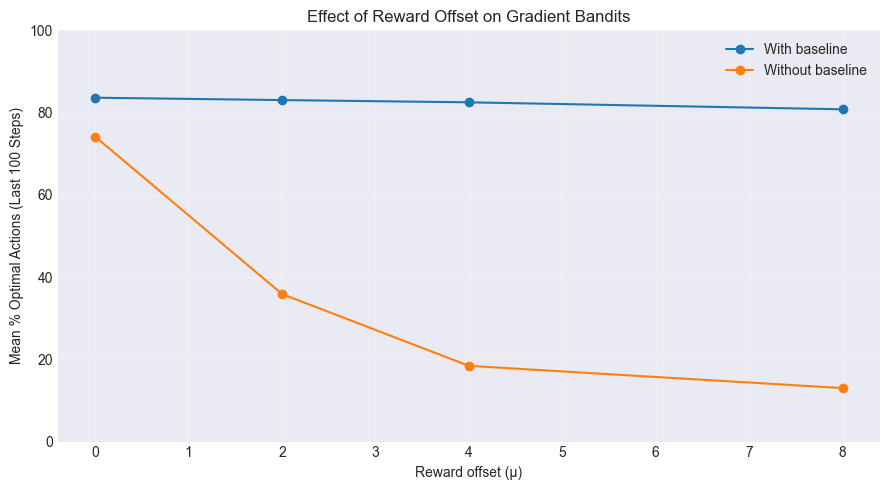

In [14]:
means_with = []
means_without = []

for mu in reward_means:
    means_with.append(
        np.mean(results[(mu, True)])
    )
    means_without.append(
        np.mean(results[(mu, False)])
    )

plt.figure(figsize=(9, 5))

plt.plot(
    reward_means,
    means_with,
    marker="o",
    label="With baseline",
)

plt.plot(
    reward_means,
    means_without,
    marker="o",
    label="Without baseline",
)

plt.xlabel("Reward offset (μ)")
plt.ylabel("Mean % Optimal Actions (Last 100 Steps)")
plt.title("Effect of Reward Offset on Gradient Bandits")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

As the reward offset increases, the gradient-bandit algorithm with a baseline maintains relatively stable performance, while the algorithm without a baseline performs progressively worse.
Let's examine the distributions of optimal-action selection frequencies across individual runs to better understand these differences.

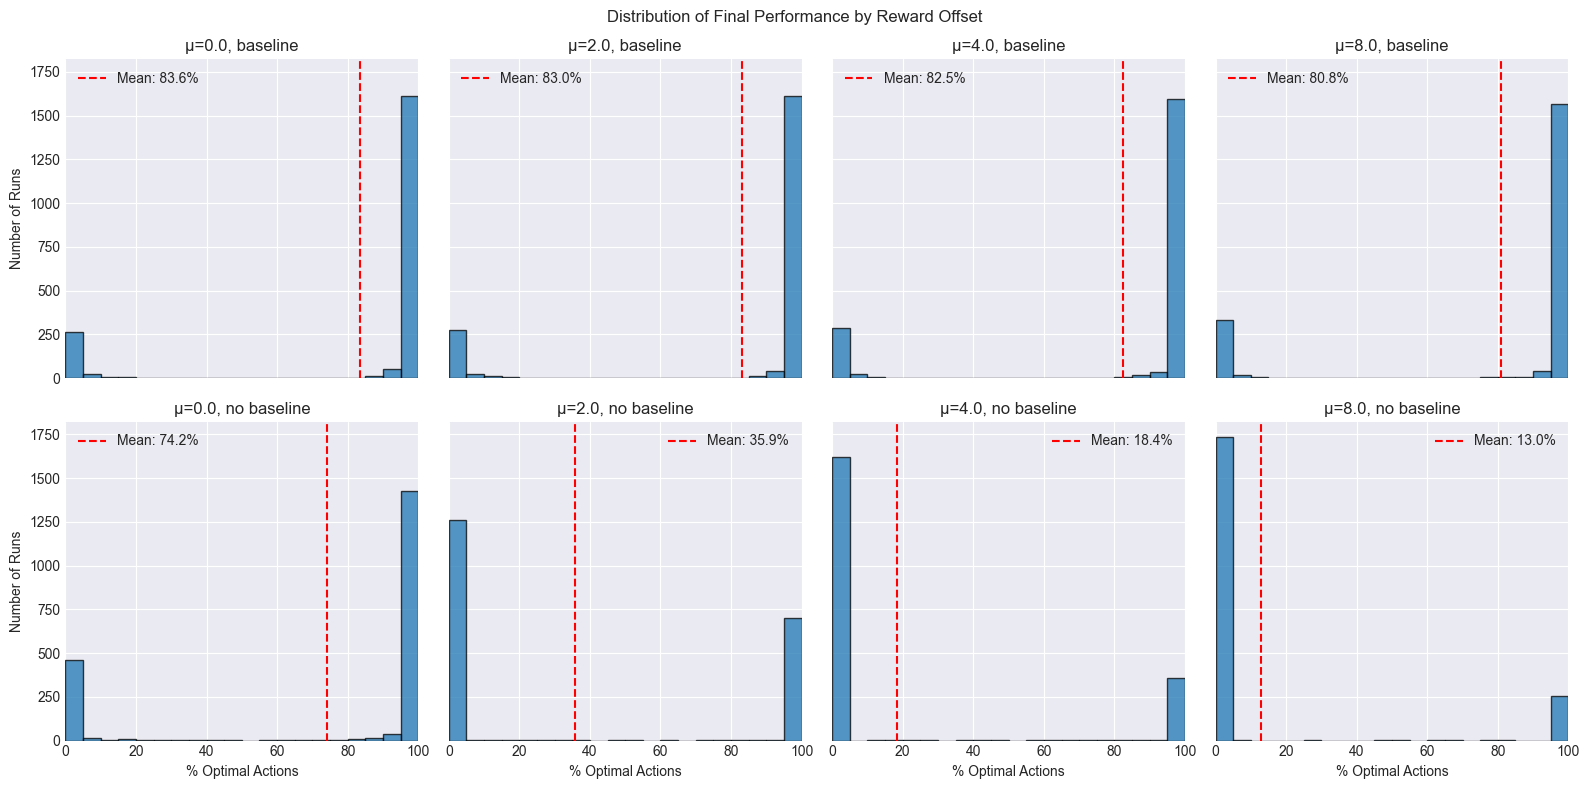

In [15]:
fig, axes = plt.subplots(
    2, 4, figsize=(16, 8),
    sharex=True,
    sharey=True,
)

bins = np.linspace(0, 100, 21)

for col, mu in enumerate(reward_means):
    for row, use_baseline in enumerate([True, False]):
        ax = axes[row, col]
        data = results[(mu, use_baseline)]

        ax.hist(
            data,
            bins=bins,
            edgecolor="black",
            alpha=0.75,
        )

        ax.axvline(
            np.mean(data),
            color="red",
            linestyle="--",
            label=f"Mean: {np.mean(data):.1f}%",
        )

        ax.set_title(
            f"μ={mu}, "
            f"{'baseline' if use_baseline else 'no baseline'}"
        )
        ax.set_xlim(0, 100)
        ax.legend()

        if row == 1:
            ax.set_xlabel("% Optimal Actions")
        if col == 0:
            ax.set_ylabel("Number of Runs")

fig.suptitle(
    "Distribution of Final Performance by Reward Offset"
)
plt.tight_layout()
plt.show()


As the reward offset increases, the distribution of optimal-action selection frequencies remains relatively stable for the gradient-bandit algorithm with a baseline. In contrast, the distribution for the algorithm without a baseline shifts dramatically toward zero, with the vast majority of runs rarely selecting the optimal action when $\mu=8$.

Now, let's plot the gradient variance across different reward offsets.

In [16]:
# Configuration
k = 10
num_samples = 100_000
reward_means = [0.0, 2.0, 4.0, 8.0]

key = jax.random.key(42)

# Fix a single bandit problem
key, env_key = jax.random.split(key)
q_base = jax.random.normal(env_key, shape=(k,))

# Fix the policy: all preferences initially zero
H = jnp.zeros(k)
probs = jax.nn.softmax(H)

# Generate shared action and reward randomness
key, action_key, noise_key = jax.random.split(key, 3)

actions = jax.random.choice(
    action_key,
    a=k,
    shape=(num_samples,),
    p=probs,
)

noise = jax.random.normal(noise_key, (num_samples,))

# Score-function gradients: ∇ log π(A)
one_hot = jax.nn.one_hot(actions, k)
score_gradients = one_hot - probs


def measure_gradient_variance(mu, use_baseline):
    # Same underlying action values, shifted by mu
    q_star = q_base + mu

    # Observed rewards
    rewards = q_star[actions] + noise

    # Exact expected reward under the fixed policy
    baseline = jnp.dot(probs, q_star) if use_baseline else 0.0

    # Stochastic gradient estimates
    gradients = (
        (rewards - baseline)[:, None] * score_gradients
    )

    # Mean gradient
    mean_gradient = jnp.mean(gradients, axis=0)

    # Total variance: sum of component variances
    total_variance = jnp.sum(
        jnp.var(gradients, axis=0)
    )

    return float(total_variance), np.asarray(mean_gradient)

In [17]:
results = {
    "With baseline": [],
    "Without baseline": [],
}

for mu in reward_means:
    for use_baseline in [True, False]:
        variance, mean_grad = measure_gradient_variance(
            mu, use_baseline
        )

        name = (
            "With baseline"
            if use_baseline
            else "Without baseline"
        )

        results[name].append(variance)

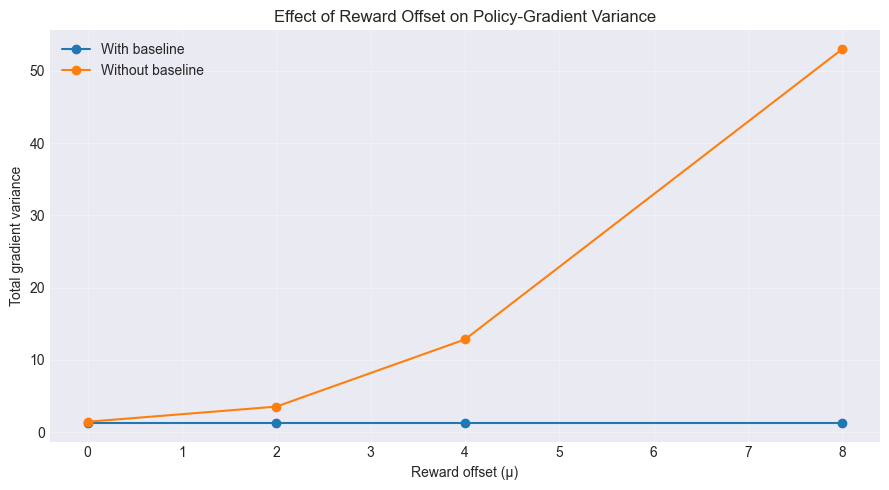

In [18]:
# Plot gradient variance
plt.figure(figsize=(9, 5))

for name, variances in results.items():
    plt.plot(
        reward_means,
        variances,
        marker="o",
        label=name,
    )

plt.xlabel("Reward offset (μ)")
plt.ylabel("Total gradient variance")
plt.title("Effect of Reward Offset on Policy-Gradient Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The gradient-bandit algorithm with a baseline maintains relatively low gradient variance across different reward offsets. In contrast, the variance of the no-baseline gradient estimator increases sharply as the reward offset grows. 

Finally, let's let's compare the policy entropy across reward offsets for both algorithms.

In [ ]:
k = 10
num_runs = 2000
num_steps = 1000
alpha = 0.1

reward_means = [0.0, 2.0, 4.0, 8.0]
baseline_options = [True, False]

# Successful = optimal action chosen at least 90%
# of the time during the final 100 steps.
success_threshold = 90.0
evaluation_window = 100


def run_experiment(key, env, agent):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    optimal_action = jnp.argmax(env_state)

    def training_step(carry, _):
        key, agent_state, env_state = carry

        key, action_key, reward_key = jax.random.split(key, 3)

        # Measure policy entropy BEFORE the action/update
        log_probs = jax.nn.log_softmax(agent_state.H)
        probs = jnp.exp(log_probs)

        entropy = -jnp.sum(probs * log_probs)

        # Select action
        action = agent.select_action(action_key, agent_state)

        # Environment interaction
        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        # Update preferences
        agent_state = agent.update(
            agent_state, action, reward
        )

        return (
            key, agent_state, env_state
        ), (
            action, entropy
        )

    initial_carry = (key, agent_state, env_state)

    _, (actions, entropies) = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    return actions, entropies, optimal_action

In [20]:
key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

results = {}

for mu in reward_means:
    env = KArmedBandit(k=k, mean=mu)

    for use_baseline in baseline_options:
        agent = GradientBanditAgent(
            k=k,
            alpha=alpha,
            use_baseline=use_baseline,
        )

        batched_experiment = jax.jit(
            jax.vmap(
                lambda run_key: run_experiment(
                    run_key, env, agent
                )
            )
        )

        actions, entropies, optimal_actions = (
            batched_experiment(keys)
        )

        # Convert to NumPy for analysis and plotting
        actions = np.asarray(actions)
        entropies = np.asarray(entropies)
        optimal_actions = np.asarray(optimal_actions)

        # Evaluate each run over its final 100 steps
        final_optimal_pct = 100 * np.mean(
            actions[:, -evaluation_window:]
            == optimal_actions[:, None],
            axis=1,
        )

        successful = (
            final_optimal_pct >= success_threshold
        )

        results[(mu, use_baseline)] = {
            "entropies": entropies,
            "final_optimal_pct": final_optimal_pct,
            "successful": successful,
        }



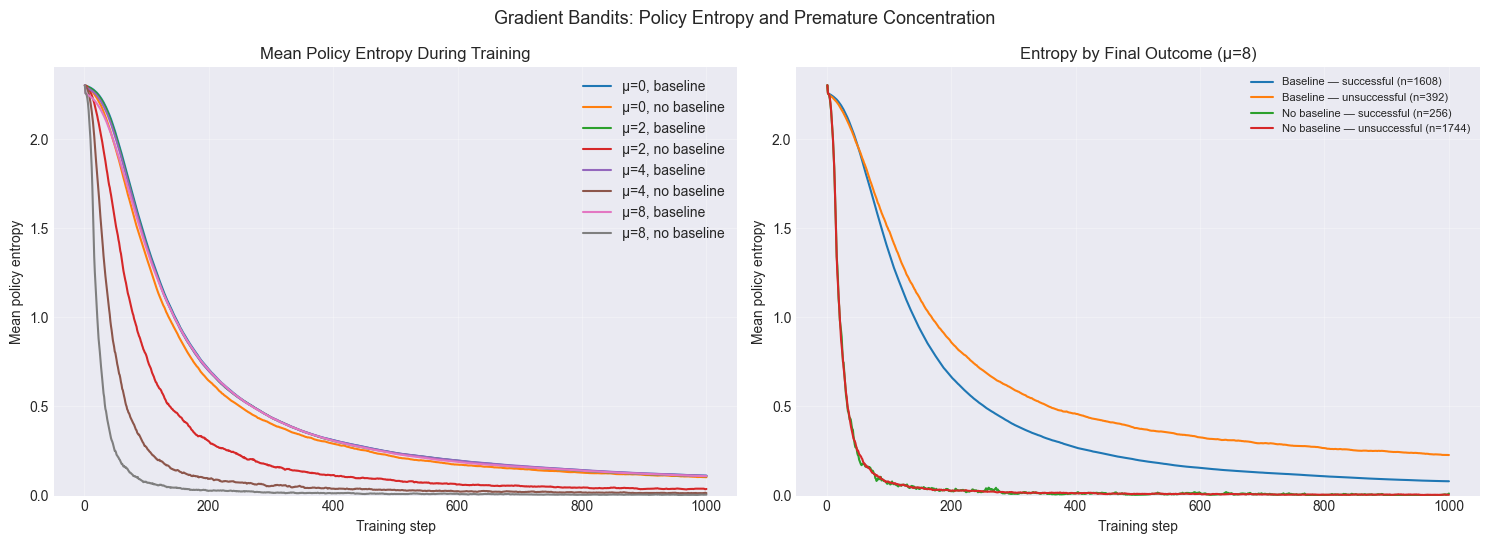

In [21]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5.5)
)

steps = np.arange(1, num_steps + 1)

ax = axes[0]

for (mu, use_baseline), result in results.items():
    mean_entropy = np.mean(
        result["entropies"], axis=0
    )

    label = (
        f"μ={mu:g}, "
        f"{'baseline' if use_baseline else 'no baseline'}"
    )

    ax.plot(
        steps,
        mean_entropy,
        label=label,
    )

ax.set_xlabel("Training step")
ax.set_ylabel("Mean policy entropy")
ax.set_title("Mean Policy Entropy During Training")
ax.set_ylim(0, np.log(k) + 0.1)
ax.grid(alpha=0.3)
ax.legend()


ax = axes[1]
mu = 8.0

for use_baseline in baseline_options:
    result = results[(mu, use_baseline)]

    entropies = result["entropies"]
    successful = result["successful"]

    for is_success, status in [
        (True, "successful"),
        (False, "unsuccessful"),
    ]:
        mask = successful == is_success
        count = np.sum(mask)

        if count == 0:
            continue

        mean_entropy = np.mean(
            entropies[mask],
            axis=0,
        )

        label = (
            f"{'Baseline' if use_baseline else 'No baseline'}"
            f" — {status} (n={count})"
        )

        ax.plot(
            steps,
            mean_entropy,
            label=label,
        )

ax.set_xlabel("Training step")
ax.set_ylabel("Mean policy entropy")
ax.set_title("Entropy by Final Outcome (μ=8)")
ax.set_ylim(0, np.log(k) + 0.1)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

fig.suptitle(
    "Gradient Bandits: Policy Entropy and Premature Concentration",
    fontsize=13,
)

plt.tight_layout()
plt.show()

The left plot shows that policy entropy collapses rapidly for the gradient-bandit algorithm without a baseline, while the baseline version maintains higher entropy for longer. The right plot reveals that this pattern persists across both successful and unsuccessful runs, suggesting that the no-baseline algorithm becomes prematurely concentrated on an action regardless of whether that action is optimal.
## Premature Policy Concentration and Recovery

Our entropy experiment revealed an interesting pattern: without a reward baseline, the gradient-bandit algorithm rapidly converged toward a low-entropy policy, regardless of whether it had identified the optimal action. But why should this be a problem? After all, the objective of a multi-armed bandit is to identify the best action and select it as frequently as possible. A nearly deterministic policy is precisely what we want provided that it favors the optimal action. The difficulty arises when the policy becomes highly concentrated on a suboptimal action early in training.

### How Softmax Concentration Affects Exploration

Recall that gradient bandits assign a preference $H(a)$ to each action and use softmax to convert preferences into probabilities:

$$
\pi(a)=\frac{\exp(H(a))}{\sum_b\exp(H(b))}
$$

Consider two actions, $a_1$ and $a_2$. Their probability ratio is:

$$
\frac{\pi(a_1)}{\pi(a_2)}
=
\exp(H(a_1)-H(a_2))
$$

Thus, differences in action preferences translate exponentially into differences in selection probabilities. For example, if one action's preference exceeds another's by 5, it is approximately 148 times more likely to be selected. If the difference is 10, it is approximately 22,026 times more likely. This means that a few large stochastic updates can make one action overwhelmingly more probable than its alternatives. Crucially, the softmax policy does not know whether that action is optimal. It only reflects the preferences learned from previous experience.

### Why Recovery Becomes Slow

The gradient-bandit update is:

$$
H_{t+1}(a)
=
H_t(a)
+
\alpha(R_t-b_t)
\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

Suppose the policy has become highly concentrated on a suboptimal action $a_s$, so that:

$$
\pi_t(a_s)\approx 1
$$

There are two reasons why recovery can become slow. First, alternative actions are rarely sampled. If the optimal action $a^*$ has a very small selection probability, the algorithm may need many steps before selecting it again.  The expected number of independent selections required to sample an action with fixed probability $p$ is:

$$
\mathbb{E}[T]=\frac{1}{p}
$$

For example, an action selected with probability $0.001$ would require 1,000 steps on average before being selected again, if its probability remained fixed. Second, the preference updates for the dominant action become small. When the dominant action is selected, its preference update is:

$$
\Delta H(a_s)
=
\alpha(R_t-b_t)(1-\pi_t(a_s))
$$

As $\pi_t(a_s)$ approaches 1, the factor $(1-\pi_t(a_s))$ approaches zero. Similarly, the update to an unselected alternative action $a$ is:

$$
\Delta H(a)
=
-\alpha(R_t-b_t)\pi_t(a)
$$

When $\pi_t(a)$ is very small, this update is also small. Consequently, a highly concentrated softmax policy can enter a regime in which the dominant action is repeatedly selected, alternative actions are seldom explored, and the usual preference updates are too small to change the policy quickly. This creates a feedback mechanism: the policy's current preferences influence the data it collects, and that data determines its subsequent preference updates.

### Connecting This to Our Experiments

We can now interpret the results of our previous experiments together. Adding a constant positive offset to the rewards increased the variance of the no-baseline gradient estimator without changing its expected value. The larger stochastic updates were associated with much more rapid policy concentration. In our entropy experiment at $\mu=8$, the no-baseline algorithm's policy entropy collapsed within roughly 100 steps, both in runs that eventually succeeded and in runs that failed.  This distinction is important. Rapid concentration was not itself evidence of successful learning. Instead, the algorithm frequently became highly confident in an action before it had reliably determined whether that action was optimal. Once a suboptimal action dominated the policy, the dynamics described above made recovery increasingly difficult within our 1,000-step training horizon. By contrast, the running-average baseline reduced the effect of the common positive reward offset. In our experiments, this was associated with more gradual policy concentration and a substantially higher probability of learning the optimal action.

### Does Premature Concentration Mean Permanent Failure?

Not necessarily. For finite action preferences, softmax assigns strictly positive probability to every action. Therefore, a suboptimal action does not become permanently inaccessible merely because its selection probability is very small. However, a small nonzero probability does not guarantee rapid recovery. An algorithm may require far more training steps than are available in a practical experiment.  Our results therefore demonstrate a finite-horizon optimization problem, not a proof that the policy-gradient algorithm must converge permanently to a suboptimal policy.

They also illustrate why matching expected gradients is insufficient to predict learning outcomes. Although two gradient estimators may have identical expectations at any fixed policy, their stochastic updates can lead them through substantially different sequences of policies.

In our experiments, the reward baseline helped prevent large, noisy updates from concentrating the policy too quickly, improving the algorithm's opportunity to discover and consistently select the optimal action.